# Fig. 1: telling adaptive mechanisms apart requires deep sampling of rare events

Panels 1b-d each overlay 50 simulated Luria-Delbruck experiments at four statistical
resolutions, N_R = 50, 500, 5000 and 50000 replicates.  Black is the canonical
spontaneous-only distribution; orange is an alternative mechanism drawn from the
literature.  The point of the sweep is that at N_R ~ 100 -- the resolution of Luria
and Delbruck's original assay and of most since -- the two are indistinguishable, and
only past N_R ~ 1000 do they separate.

The three alternatives, with the parameters of SI section 1.6 and N = 1e6 throughout:

  1b  drug-induced mutations.  A Poisson(mu_ind * N) component on top of the
      spontaneous background, mu_ind = 5e-6.  The spontaneous rate is lowered to
      1e-6 so the total number of mutations stays comparable to the canonical curve,
      isolating the change in shape from a change in scale.

  1c  a phenotypic delay of 2.5 generations between mutation and expression of
      resistance, with mu raised to 7e-6 for the same reason.

  1d  reversible phenotypic switching rather than genetic mutation, entering as an
      effective fitness sigma = 0.7 -- equivalent to a reversion rate nu = 0.3, about
      a three-generation memory.

Runtime: ~2 min.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import sys, time

import numpy as np
import matplotlib.pyplot as plt

from barfly.ld import simulate_ld_extended                      # noqa: E402
from barfly.plotting import colorTable, use_paper_style         # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
use_paper_style()

MU_CANONICAL = 2.5e-6
MU_INDUCED_BG, MU_INDUCED = 1e-6, 5e-6
PREFITNESS = 0.7          # sigma; equivalently nu = 0.3 (SI section 1.6)
DELAY, MU_DELAY = 2.5, 7e-6
N_EXPT, N_REP, N_POP = 50, 100_000, 1e6
SUBSAMPLES = [50, 500, 5000, 50000]     # N_R
SEED = 20260907

rng = np.random.default_rng(SEED)
t_start = time.time()

canonical, induced, switching, delayed = {}, {}, {}, {}

In [2]:
def panel(alternative, fname, ylim):
    fig, axs = plt.subplots(1, 4, sharey=True, sharex=True)
    fig.set_size_inches(11, 2.5)
    for j, subsample in enumerate(SUBSAMPLES):
        for expt in range(N_EXPT):
            for series, colour in ((canonical, "k"), (alternative, colorTable['o'])):
                mvals = np.sort(series[expt][:subsample])
                axs[j].step(mvals, np.arange(subsample)[::-1] / subsample,
                            color=colour, alpha=0.1, rasterized=True)
        axs[j].set_yscale("log"); axs[j].set_xscale("log")
        axs[j].set_ylim(ylim); axs[j].set_xlim([1, 3e3])
        axs[j].set_xticks([1, 10, 100, 1000])
    plt.tight_layout()
    plt.savefig(OUT / fname, dpi=400)
    plt.show()

  10/50 experiments simulated (8s)


  20/50 experiments simulated (17s)


  30/50 experiments simulated (26s)


  40/50 experiments simulated (34s)


  50/50 experiments simulated (43s)


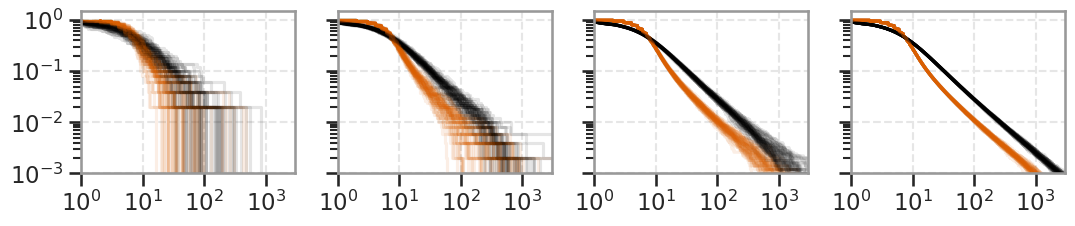

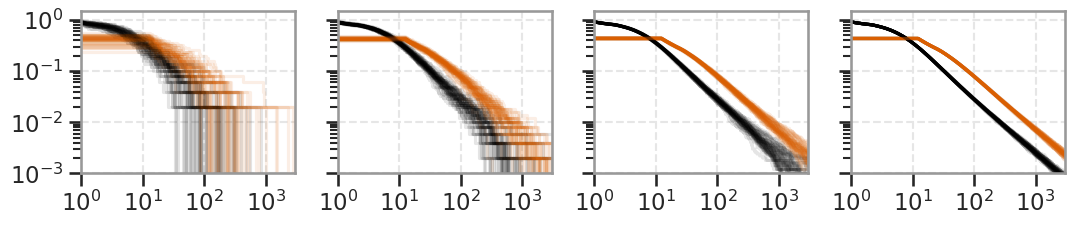

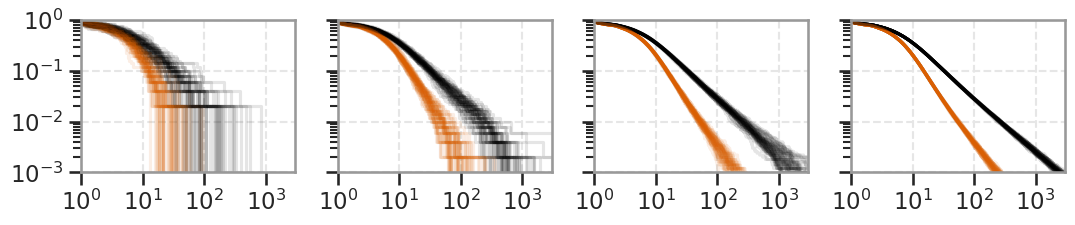

Done in 51s.


In [3]:
sys.path.insert(0, str(ROOT))
from barfly.ld import simulate_ld_extended                      # noqa: E402
from barfly.plotting import colorTable, use_paper_style         # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
use_paper_style()

MU_CANONICAL = 2.5e-6
MU_INDUCED_BG, MU_INDUCED = 1e-6, 5e-6
PREFITNESS = 0.7          # sigma; equivalently nu = 0.3 (SI section 1.6)
DELAY, MU_DELAY = 2.5, 7e-6
N_EXPT, N_REP, N_POP = 50, 100_000, 1e6
SUBSAMPLES = [50, 500, 5000, 50000]     # N_R
SEED = 20260907

rng = np.random.default_rng(SEED)
t_start = time.time()

canonical, induced, switching, delayed = {}, {}, {}, {}
for expt in range(N_EXPT):
    canonical[expt] = simulate_ld_extended([MU_CANONICAL], [1], n_replicates=N_REP,
                                           population_size=N_POP, rng=rng)
    induced[expt] = simulate_ld_extended([MU_INDUCED_BG], [1], mu_induced=MU_INDUCED,
                                         n_replicates=N_REP, population_size=N_POP, rng=rng)
    switching[expt] = simulate_ld_extended([MU_CANONICAL], [PREFITNESS], n_replicates=N_REP,
                                           population_size=N_POP, rng=rng)
    delayed[expt] = simulate_ld_extended([MU_DELAY], [1], phenotypic_delay=DELAY,
                                         n_replicates=N_REP, population_size=N_POP, rng=rng)
    if (expt + 1) % 10 == 0:
        print(f"  {expt+1}/{N_EXPT} experiments simulated "
              f"({time.time()-t_start:.0f}s)", flush=True)

def panel(alternative, fname, ylim):
    fig, axs = plt.subplots(1, 4, sharey=True, sharex=True)
    fig.set_size_inches(11, 2.5)
    for j, subsample in enumerate(SUBSAMPLES):
        for expt in range(N_EXPT):
            for series, colour in ((canonical, "k"), (alternative, colorTable['o'])):
                mvals = np.sort(series[expt][:subsample])
                axs[j].step(mvals, np.arange(subsample)[::-1] / subsample,
                            color=colour, alpha=0.1, rasterized=True)
        axs[j].set_yscale("log"); axs[j].set_xscale("log")
        axs[j].set_ylim(ylim); axs[j].set_xlim([1, 3e3])
        axs[j].set_xticks([1, 10, 100, 1000])
    plt.tight_layout()
    plt.savefig(OUT / fname, dpi=400)
    plt.show()

panel(induced,   "fig01b_LD_with_induced.svg",   [1e-3, 1.5])
panel(delayed,   "fig01c_LD_with_delay.svg",     [1e-3, 1.5])
panel(switching, "fig01d_LD_with_switching.svg", [1e-3, 1])   # note: ylim 1, not 1.5

print(f"Done in {time.time()-t_start:.0f}s.")